# Предсказание калорийности блюд

Выполнил: Репко А.А.

### **Описание задачи**
Задача состоит в создании и обучении нейросети, которая будет предсказывать калорийность блюд. Полученную модель можно интегрировать во многие fitness и health-приложения, она будет полезна тем, кто следит за своим здоровьем. 

### **Цель**
Получить DL-модель, способную оценить калорийность блюда.

### **Целевая метрика**
Модель будет считаться готовой к интеграции в продукт при точности оценки `MAE < 50` (MAE — Mean Absolute Error) на тестовой выборке. 

### **Датасет**
Датасет содержит фотографии блюд, описание ингредиентов, а также общую массу порции и калорийность.

## Этап 1. Исследовательский анализ данных

## 0. Установка библиотек и загрузка датасета

In [1]:
![ -d Nutrition ] || git clone https://github.com/andr3w13/Nutrition.git
%cd Nutrition
%pip install -q -r requirements.txt

Cloning into 'Nutrition'...
remote: Enumerating objects: 48, done.
remote: Counting objects: 100% (48/48), done.
remote: Compressing objects: 100% (31/31), done.
remote: Total 48 (delta 19), reused 41 (delta 12), pack-reused 0 (from 0)
Receiving objects: 100% (48/48), 3.29 MiB | 26.15 MiB/s, done.
Resolving deltas: 100% (19/19), done.
/content/Nutrition


In [2]:
import zipfile
from pathlib import Path

import gdown
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

pd.set_option("display.max_colwidth", 150)
plt.rcParams.update({
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})
BLUE, ORANGE = "#2a78d6", "#eb6834"

In [3]:
GDRIVE_FILE_ID = "19cIhxmvhRVpRqGHnBCbxLEfEZ51jvsTG"
ARCHIVE = Path("nutrition.zip")
DATA_DIR = Path("data")

if not (DATA_DIR / "dish.csv").exists():
    if not ARCHIVE.exists():
        gdown.download(id=GDRIVE_FILE_ID, output=str(ARCHIVE), quiet=False)
    with zipfile.ZipFile(ARCHIVE) as zf:
        zf.extractall(".")

Downloading...
From (original): https://drive.google.com/uc?id=19cIhxmvhRVpRqGHnBCbxLEfEZ51jvsTG
From (redirected): https://drive.google.com/uc?id=19cIhxmvhRVpRqGHnBCbxLEfEZ51jvsTG&confirm=t&uuid=ac857fff-07bd-406d-b7c9-49962d5c1857
To: /content/Nutrition/nutrition.zip
100%|██████████| 1.43G/1.43G [00:09<00:00, 152MB/s] 


## 1. Первый взгляд на таблицы

In [4]:
dish = pd.read_csv(DATA_DIR / "dish.csv")
ingredients = pd.read_csv(DATA_DIR / "ingredients.csv")
print("dish.csv:", dish.shape)
print("ingredients.csv:", ingredients.shape)
dish.head()

dish.csv: (3262, 5)
ingredients.csv: (555, 2)


,dish_id,total_calories,total_mass,ingredients,split
0,dish_1561662216,300.794281,193.0,ingr_0000000508;ingr_0000000122;ingr_0000000026;ingr_0000000524;ingr_0000000094;ingr_0000000023;ingr_0000000189;ingr_0000000054;ingr_0000000029;in...,test
1,dish_1561662054,419.438782,292.0,ingr_0000000312;ingr_0000000026;ingr_0000000029;ingr_0000000122;ingr_0000000508;ingr_0000000513;ingr_0000000520;ingr_0000000525;ingr_0000000161;in...,train
2,dish_1562008979,382.936646,290.0,ingr_0000000448;ingr_0000000520;ingr_0000000462;ingr_0000000514;ingr_0000000152;ingr_0000000312;ingr_0000000291;ingr_0000000045;ingr_0000000122;in...,test
3,dish_1560455030,20.590000,103.0,ingr_0000000471;ingr_0000000031;ingr_0000000347,train
4,dish_1558372433,74.360001,143.0,ingr_0000000453,train


In [5]:
ingredients.head()

,id,ingr
0,1,cottage cheese
1,2,strawberries
2,3,garden salad
3,4,bacon
4,5,potatoes


In [6]:
dish.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3262 entries, 0 to 3261
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   dish_id         3262 non-null   object 
 1   total_calories  3262 non-null   float64
 2   total_mass      3262 non-null   float64
 3   ingredients     3262 non-null   object 
 4   split           3262 non-null   object 
dtypes: float64(2), object(3)
memory usage: 127.6+ KB


In [7]:
dish["split"].value_counts()

,count
split,
train,2755
test,507


В датасете 3262 блюда и 555 ингредиентов, пропусков нет, типы колонок нормальные, в train - 2755 блюд, в test - 507.

## 2. Проверка качества данных

In [8]:
print("Дубликатов dish_id:", dish["dish_id"].duplicated().sum())
print("Дубликатов id ингредиента:", ingredients["id"].duplicated().sum())

image_ids = {p.name for p in (DATA_DIR / "images").iterdir()}
print("Блюд без фото:", (~dish["dish_id"].isin(image_ids)).sum())
print("Папок с фото, которых нет в dish.csv:", len(image_ids - set(dish["dish_id"])))

Дубликатов dish_id: 0
Дубликатов id ингредиента: 0
Блюд без фото: 0
Папок с фото, которых нет в dish.csv: 228


In [9]:
ingredients[ingredients["ingr"].duplicated(keep=False)]

,id,ingr
230,231,deprecated
452,453,deprecated
457,458,deprecated
469,470,deprecated


In [10]:
dish_ingr_ids = dish["ingredients"].str.split(";").apply(lambda ids: {int(i.replace("ingr_", "")) for i in ids})
deprecated = set(ingredients.loc[ingredients["ingr"] == "deprecated", "id"])

print("Блюда, где встречается deprecated:", dish_ingr_ids.apply(lambda ids: bool(ids & deprecated)).sum())
print("Блюда, где все ингредиенты deprecated:", dish_ingr_ids.apply(lambda ids: ids <= deprecated).sum())

used = set().union(*dish_ingr_ids)
print("Уникальных ингредиентов в блюдах:", len(used), "из", len(ingredients))
print("Все ID есть в ingredients.csv:", used <= set(ingredients["id"]))

train_ids = set().union(*dish_ingr_ids[dish["split"] == "train"])
test_ids = set().union(*dish_ingr_ids[dish["split"] == "test"])
print("Ингредиентов из test, которых нет в train:", len(test_ids - train_ids))

Блюда, где встречается deprecated: 31
Блюда, где все ингредиенты deprecated: 16
Уникальных ингредиентов в блюдах: 200 из 555
Все ID есть в ingredients.csv: True
Ингредиентов из test, которых нет в train: 2


С данными в целом всё хорошо, у каждого блюда есть фото, а 228 лишних папок с фотографиями просто не используются. Все ID ингредиентов из `dish.csv` находятся в справочнике.

В справочнике 4 ингредиента называются `deprecated`. Они встречаются в 31 блюде, а 16 блюд целиком из них состоят, для текстовой части модели такое слово бесполезно, поэтому при объединении таблиц выкинем его. У этих 16 блюд текст будет пустым, и модель будет опираться на фото и массу.

Ещё видно, что в блюдах используется только 200 ингредиентов из 555, а в test почти нет ингредиентов, которых не было бы в train (всего 2). Значит, текстовая часть на тесте не столкнётся с незнакомыми продуктами.

## 3. Целевая переменная и масса порции

In [11]:
dish[["total_calories", "total_mass"]].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).round(1)

,total_calories,total_mass
count,3262.0,3262.0
mean,255.0,215.0
std,219.6,161.5
min,0.0,1.0
1%,6.4,14.0
25%,80.1,92.0
50%,209.1,177.0
75%,375.1,305.0
99%,918.5,702.3
max,3943.3,3051.0


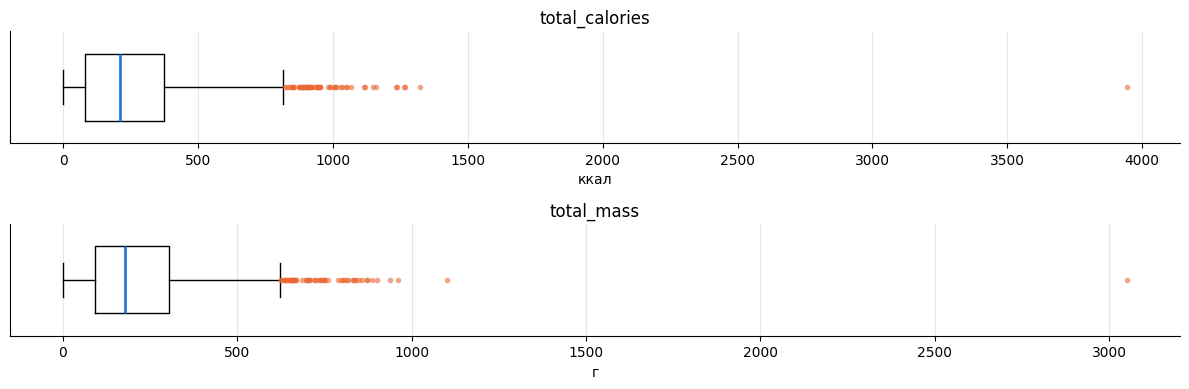

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(12, 4))
for ax, col, xlabel in [(axes[0], "total_calories", "ккал"), (axes[1], "total_mass", "г")]:
    ax.boxplot(dish[col], vert=False, widths=0.6,
               flierprops=dict(marker="o", markersize=4, markerfacecolor=ORANGE, markeredgecolor="none", alpha=0.6),
               medianprops=dict(color=BLUE, linewidth=2))
    ax.set(title=col, xlabel=xlabel, yticks=[])
plt.tight_layout()
plt.show()

Из boxplot видно, что есть 1 серьезный выброс в калориях (~3950 ккал) и 2 в массе (> 1000 г). Посмотрим на распределения этих двух величин (не учитывая выбросы):

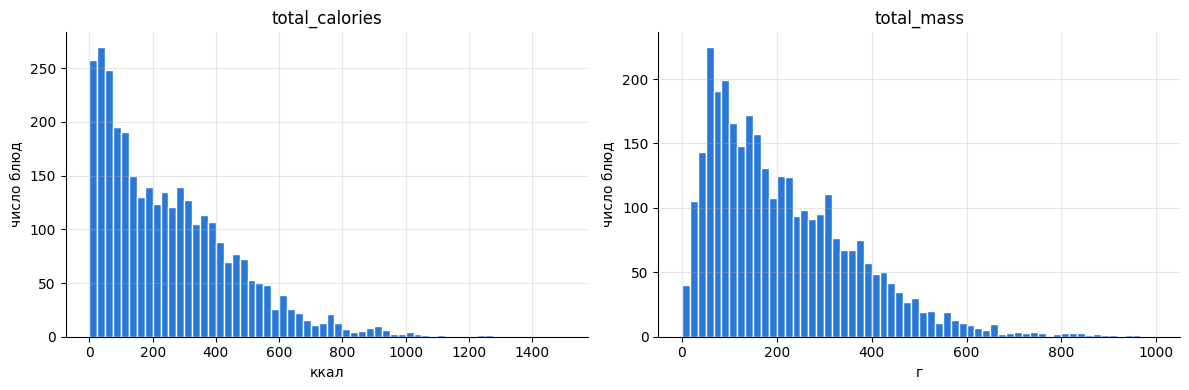

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(dish["total_calories"], bins=60, range=(0, 1500), color=BLUE, edgecolor="white")
axes[0].set(title="total_calories", xlabel="ккал", ylabel="число блюд")
axes[1].hist(dish["total_mass"], bins=60, range=(0, 1000), color=BLUE, edgecolor="white")
axes[1].set(title="total_mass", xlabel="г", ylabel="число блюд")
plt.tight_layout()
plt.show()

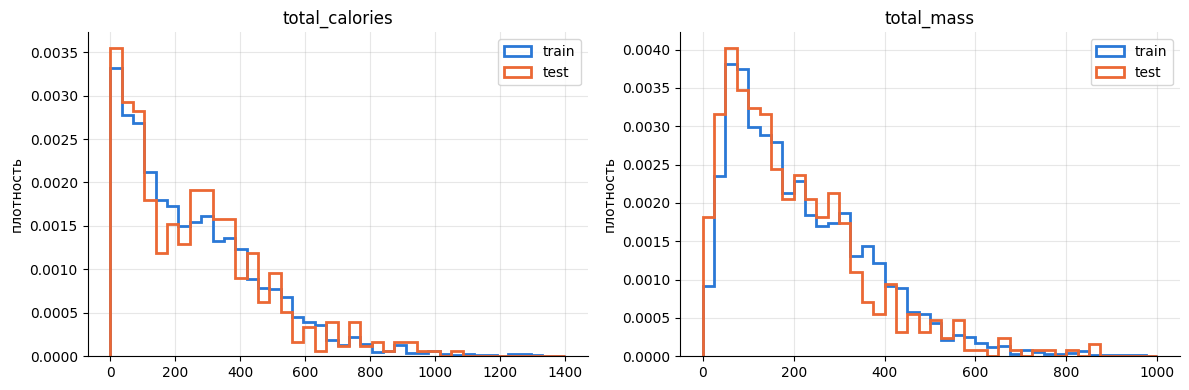

total_calories        total_mass       
                mean median       mean median
split                                        
test           255.5  226.0      198.5  161.0
train          254.9  208.1      218.0  179.0

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, rng in [(axes[0], "total_calories", (0, 1400)), (axes[1], "total_mass", (0, 1000))]:
    for split, color in [("train", BLUE), ("test", ORANGE)]:
        ax.hist(dish.loc[dish["split"] == split, col], bins=40, range=rng, density=True,
                histtype="step", linewidth=2, color=color, label=split)
    ax.set(title=col, ylabel="плотность")
    ax.legend()
plt.tight_layout()
plt.show()

dish.groupby("split")[["total_calories", "total_mass"]].agg(["mean", "median"]).round(1)

In [15]:
dish.sort_values("total_calories", ascending=False).head(5)[["dish_id", "total_calories", "total_mass", "split"]]

,dish_id,total_calories,total_mass,split
1518,dish_1560974769,3943.325195,3051.0,train
124,dish_1565033265,1324.084961,625.0,train
2753,dish_1562603895,1268.157349,517.0,train
1125,dish_1564170010,1264.548340,831.0,train
1951,dish_1563476577,1238.033691,857.0,train


In [16]:
low = dish[dish["total_calories"] < 5][["dish_id", "total_calories", "total_mass", "ingredients"]]

# Добавление названий ингредиентов
ingr_ids = low["ingredients"].str.split(";").explode().str.replace("ingr_", "").astype(int)
names = ingr_ids.to_frame("id").merge(ingredients, on="id", how="left").set_index(ingr_ids.index)["ingr"]
low["ingredients"] = names.groupby(level=0).agg(", ".join)
low

,dish_id,total_calories,total_mass,ingredients
26,dish_1558549773,2.30,10.0,spinach (raw)
195,dish_1558461431,1.15,5.0,spinach (raw)
263,dish_1557861216,0.00,1.0,plate only
505,dish_1558629644,4.20,15.0,mixed greens
906,dish_1558462036,2.99,13.0,spinach (raw)
1086,dish_1562959295,3.04,19.0,radishes
1209,dish_1558548958,2.30,10.0,spinach (raw)
1311,dish_1556575124,4.48,28.0,celery
1351,dish_1558458438,3.22,14.0,spinach (raw)
1421,dish_1558641211,3.28,8.0,carrot


Распределение калорийности сильно скошено вправо, медиана около 209 ккал, среднее 255, у 99% блюд меньше 920 ккал, у массы картина похожая. Train и test распределены почти одинаково, значит, тест репрезентативный.

Выделяется одно блюдо `dish_1560974769` на 3943 ккал и 3051 г, также есть 25 блюд меньше 5 ккал. Это порции в несколько граммов из одного продукта (шпинат, огурцы, зелень) и пара блюд с ингредиентом `plate only` и нулевой калорийностью, т.е. по сути пустая тарелка.

## 4. Связь калорийности и массы

Pearson's r = 0.76


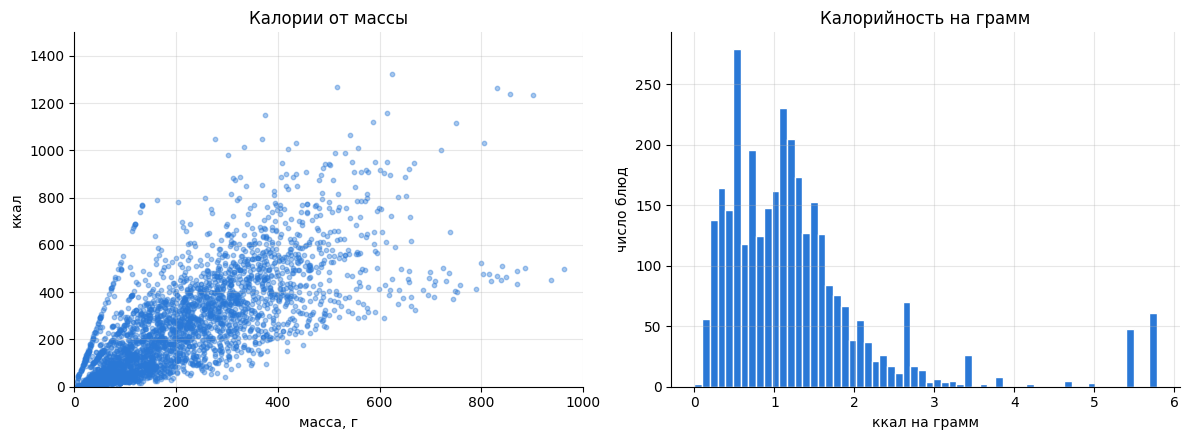

,kcal_per_g
count,3262.00
mean,1.30
std,1.07
min,0.00
25%,0.60
50%,1.10
75%,1.56
max,5.78


In [17]:
print("Pearson's r =", round(dish["total_calories"].corr(dish["total_mass"]), 3))

dish["kcal_per_g"] = dish["total_calories"] / dish["total_mass"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(dish["total_mass"], dish["total_calories"], s=10, alpha=0.4, color=BLUE)
axes[0].set(xlim=(0, 1000), ylim=(0, 1500), xlabel="масса, г", ylabel="ккал",
            title="Калории от массы")
axes[1].hist(dish["kcal_per_g"], bins=60, color=BLUE, edgecolor="white")
axes[1].set(xlabel="ккал на грамм", ylabel="число блюд", title="Калорийность на грамм")
plt.tight_layout()
plt.show()

dish["kcal_per_g"].describe().round(2)

Масса сильно связана с калорийностью, корреляция около 0.76, поэтому `total_mass` надо подавать в модель как отдельный числовой признак.

При этом на графике видно, что при одной и той же массе калорийность может отличаться в разы. Плотность варьируется от 0 до почти 6 ккал на грамм, медиана около 1.1.

## 5. Объединение `dish.csv` и `ingredients.csv`

Ингредиенты `deprecated` пропускаются.

In [18]:
id2name = dict(zip(ingredients["id"], ingredients["ingr"]))


def ingredients_to_text(ingr_ids):
    names = [id2name[int(i.replace("ingr_", ""))] for i in ingr_ids.split(";")]
    return ", ".join(n for n in names if n != "deprecated")


df = dish.copy()
df["ingredients"] = df["ingredients"].apply(ingredients_to_text)

df.head(10)

,dish_id,total_calories,total_mass,ingredients,split,kcal_per_g
0,dish_1561662216,300.794281,193.0,"soy sauce, garlic, white rice, parsley, onions, brown rice, vinegar, apple, mixed greens, sugar, salt, lemon juice, olive oil, pork, bok choy, pep...",test,1.558520
1,dish_1561662054,419.438782,292.0,"pepper, white rice, mixed greens, garlic, soy sauce, millet, lemon juice, bok choy, olive oil, onions, vinegar, green beans, pork, apple, sugar, s...",train,1.436434
2,dish_1562008979,382.936646,290.0,"jalapenos, lemon juice, pork, wheat berry, cabbage, pepper, salt, carrot, garlic, caesar salad, olive oil, parsley, mayonnaise",test,1.320471
3,dish_1560455030,20.590000,103.0,"cherry tomatoes, cucumbers, baby carrots",train,0.199903
4,dish_1558372433,74.360001,143.0,,train,0.520000
5,dish_1565640549,45.482903,139.0,"tomatoes, cilantro, olive oil, mustard greens, lemon juice, onions, cucumbers, salt, arugula, jalapenos, asparagus, lime, mangos, cherry tomatoes",train,0.327215
6,dish_1563207364,309.269989,271.0,"scrambled eggs, yam, grapes, egg whites, olive oil, sweet potato",train,1.141218
7,dish_1561575474,120.058434,183.0,"salt, eggplant, roasted potatoes, cauliflower, olive oil",train,0.656057
8,dish_1563216717,246.007996,332.0,"garlic, squash, cherry tomatoes, chicken breast, spinach (raw), parmesan cheese, wheat berry, olive oil, thyme, honeydew melons, salt, broccoli",train,0.740988
9,dish_1565972591,195.199997,122.0,chicken apple sausage,train,1.600000


In [19]:
print("Кол-во Deprecated:", (df["ingredients"] == "").sum())

Кол-во Deprecated: 16


## 6. Ингредиенты

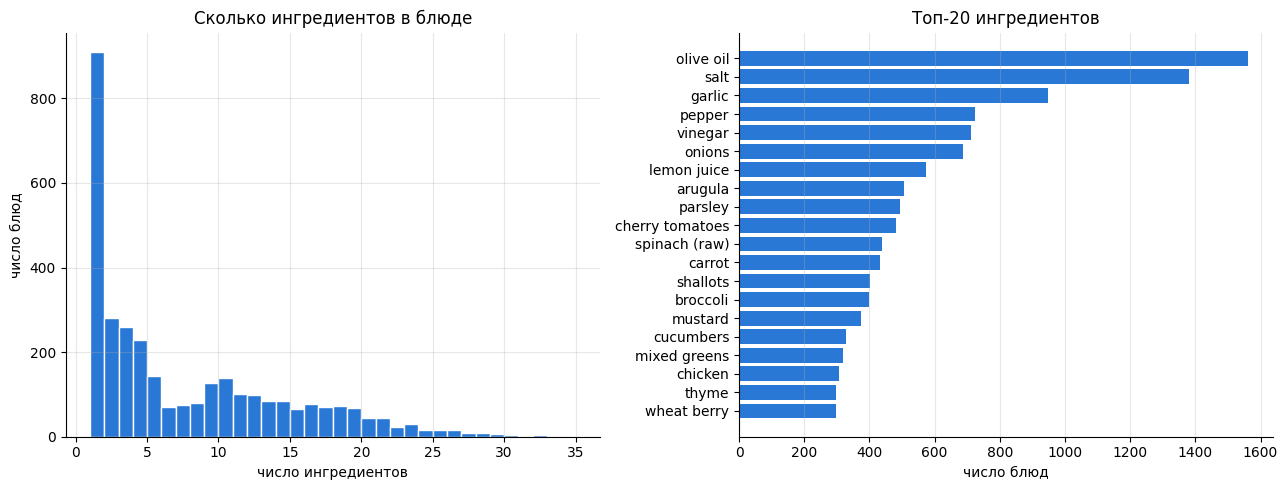

Блюд из одного ингредиента: 910


In [20]:
df["n_ingr"] = dish["ingredients"].str.count(";") + 1

all_ingr = df["ingredients"].str.split(", ").explode()
top_ingr = all_ingr[all_ingr != ""].value_counts().head(20)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(df["n_ingr"], bins=range(1, 36), color=BLUE, edgecolor="white")
axes[0].set(xlabel="число ингредиентов", ylabel="число блюд", title="Сколько ингредиентов в блюде")
axes[1].barh(top_ingr.index[::-1], top_ingr.values[::-1], color=BLUE)
axes[1].set(xlabel="число блюд", title="Топ-20 ингредиентов")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

print("Блюд из одного ингредиента:", (df["n_ingr"] == 1).sum())

In [21]:
df.groupby(pd.cut(df["n_ingr"], [0, 1, 5, 10, 40]), observed=True)["total_calories"].agg(["count", "median"]).round(1)

,count,median
n_ingr,,
"(0, 1]",910,64.9
"(1, 5]",912,203.0
"(5, 10]",489,264.1
"(10, 40]",951,360.2


Заметная группа блюд (910 штук, 28%) состоит из одного продукта, и они в среднем гораздо легче. Чем больше ингредиентов, тем выше медианная калорийность, так что длина списка тоже несёт информацию.

Чаще всего встречаются оливковое масло, соль, чеснок, перец и уксус.

## 7. Фотографии

In [22]:
def image_path(dish_id):
    return DATA_DIR / "images" / dish_id / "rgb.png"


def load_image(dish_id):
    return Image.open(image_path(dish_id)).convert("RGB")


sizes = pd.Series([Image.open(image_path(i)).size for i in df["dish_id"]]).value_counts()
sizes

,count
"(640, 480)",3262


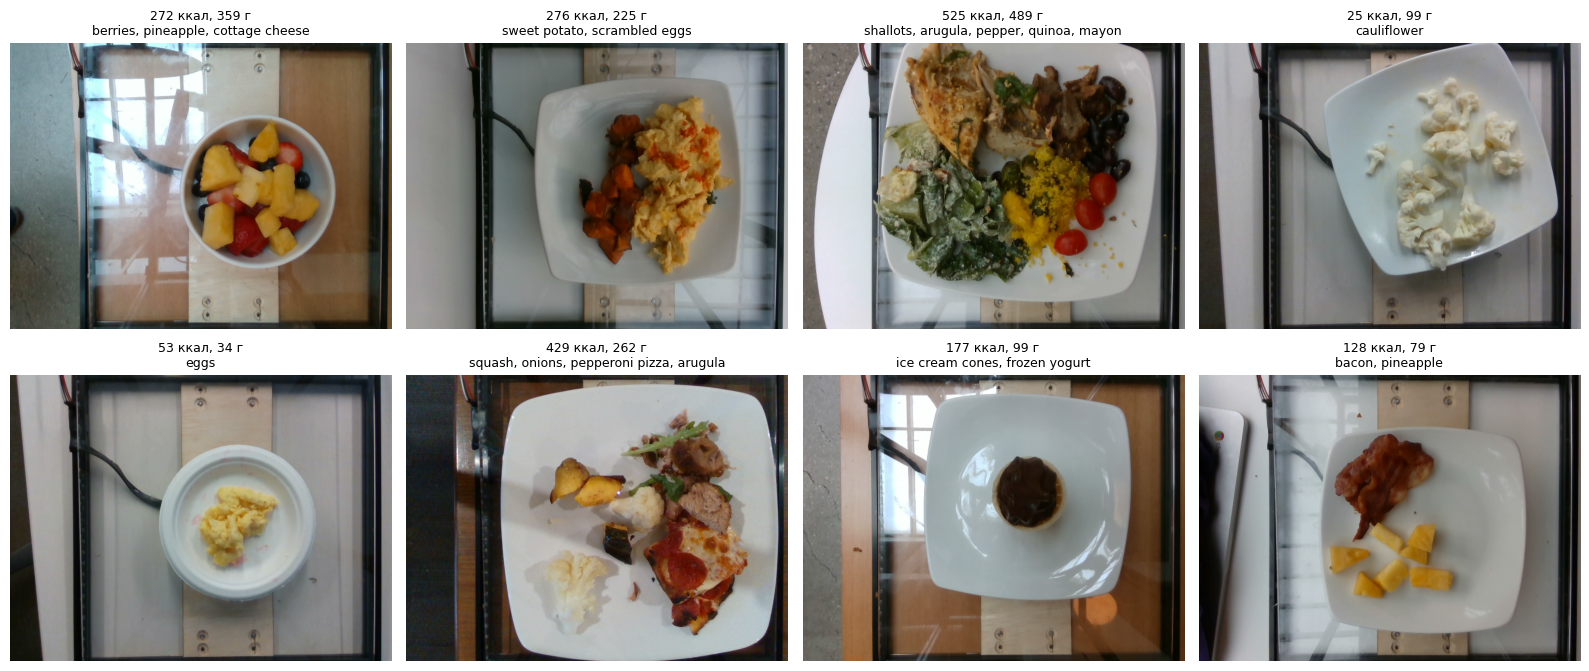

In [23]:
sample = df.sample(8, random_state=42)

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(load_image(row["dish_id"]))
    ax.set_title(f"{row['total_calories']:.0f} ккал, {row['total_mass']:.0f} г\n{row['ingredients'][:40]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

Все фотографии одного размера 640x480 и сняты сверху одной камерой, блюда стоят на одном и том же столе, в основном на белых тарелках и в мисках разной формы.

Посмотрим на аномальное блюдо с 3943 ккал:

dish_id                                                                                                                                          dish_1560974769
total_calories                                                                                                                                       3943.325195
total_mass                                                                                                                                                3051.0
split                                                                                                                                                      train
ingredients       spinach (raw), tortilla chips, corn, cheese, white rice, cherry tomatoes, lime, tomatoes, chili, garlic, salt, sour cream, onions, black beans


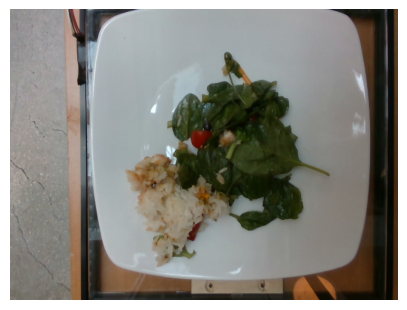

In [24]:
outlier = df.loc[df["total_calories"].idxmax()]
print(outlier[["dish_id", "total_calories", "total_mass", "split", "ingredients"]].to_string())

plt.figure(figsize=(5, 4))
plt.imshow(load_image(outlier["dish_id"]))
plt.axis("off")
plt.show()

Блюдо с 3943 ккал оказалось явной ошибкой разметки. На фото небольшая порция шпината с рисом на обычной тарелке, а по таблице там 3 кг еды и 14 ингредиентов вроде чипсов, сыра и фасоли. Это блюдо лежит в train, поэтому нужно его убрать, иначе оно сильно исказит лосс.

## 8. Видение решения

### Как решать задачу

Задача мультимодальная, поэтому архитектура будет выглядеть так:

- Изображение кодируется предобученной EfficientNet-B3 (`efficientnet_b3` из `timm`) на картинках 300x300, все слои заморожены, кроме двух последних блоков (`blocks.5`, `blocks.6`) и финальной свёртки `conv_head`.
- Список ингредиентов кодируется предобученным `bert-base-uncased` из `transformers` и берется эмбеддинг CLS-токена, дообучаются только два последних слоя энкодера (10 и 11).
- Масса порции подается как отдельный числовой признак в кг, т.к. это самый сильный признак из всех.
- Эмбеддинги проецируются линейными слоями в размерность 256, склеиваются с массой и подаются в MLP-голову, которая выдаёт калорийность на грамм.

Для валидации берём 15% блюд из train, а test используется только один раз для финальной оценки. Модель предсказывает не калорийность целиком, а калорийность на грамм, которую потом умножаем на массу порции. Так модели не нужно самой учиться масштабу порции, ей остаётся понять по фото и ингредиентам, насколько калорийна еда.

### Обогащение и аугментация данных

Обогащение данных:
- ID ингредиентов заменены на названия, без этого текстовая часть бессмысленна.

Аугментации изображений:
- Горизонтальные и вертикальные отражения, повороты на 90°, это заметно увеличивает разнообразие.
- Небольшие изменения яркости и контраста, потому что освещение на снимках немного отличается.

Аугментация текста: 
- Порядок ингредиентов в списке ничего не значит, поэтому будем случайно перемешивать его при обучении.

### Метрики

Основная метрика это MAE, в качестве лосса берём L1 (`nn.L1Loss`), он напрямую оптимизирует MAE и меньше реагирует на оставшиеся выбросы, чем MSE. Дополнительно будем смотреть RMSE, чтобы видеть, нет ли у модели редких, но очень больших ошибок, лучшую эпоху выбираем по MAE на валидации.

## Выводы

- В датасете 3262 блюда (2755 train и 507 test), пропусков и дубликатов нет, у каждого блюда есть фото 640x480, снятое сверху одной камерой в одинаковом масштабе.
- Калорийность скошена вправо (медиана 209, среднее 255 ккал), распределения train и test совпадают.
- Масса порции сильно коррелирует с калорийностью (0.76), поэтому её нужно подавать в модель отдельным признаком. Плотность блюд при этом сильно различается, и эту часть информации модель должна взять из фото и текста.
- Найдена явная ошибка разметки `dish_1560974769` (3943 ккал и 3051 г при маленькой порции на фото), её нужно убрать из train. Также в справочнике есть 4 ингредиента `deprecated`, их удаляем из текста.
- Таблицы объединены, ID ингредиентов заменены на названия через запятую, получился осмысленный текстовый вход.
- Для решения будет использоваться мультимодальная модель (EfficientNet-B3 для фото, `bert-base-uncased` для ингредиентов, масса как число, MLP-голова, которая предсказывает калорийность на грамм), аугментации фото через отражения, повороты на 90 градусов, легкий color jitter, перемешивание ингредиентов в тексте, а также L1 лосс и MAE как основная метрика.

## Этап 3. Обучение модели

## 1. Подготовка окружения

In [25]:
import os
import shutil

import torch

## 2. Обучение

In [26]:
from scripts.config import Config

In [27]:
from scripts.utils import train

model, history = train(Config)

Устройство cuda


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

... (3 outputs left out)

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B / 49.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Эпоха 1/30 | train loss 91.12 | val MAE 62.19 | val RMSE 99.65
Эпоха 2/30 | train loss 68.55 | val MAE 55.76 | val RMSE 82.93
Эпоха 3/30 | train loss 63.79 | val MAE 49.21 | val RMSE 75.43
Эпоха 4/30 | train loss 56.89 | val MAE 62.17 | val RMSE 95.94
Эпоха 5/30 | train loss 51.39 | val MAE 44.73 | val RMSE 72.12
Эпоха 6/30 | train loss 48.63 | val MAE 41.62 | val RMSE 64.89
Эпоха 7/30 | train loss 43.77 | val MAE 46.60 | val RMSE 72.57
Эпоха 8/30 | train loss 44.14 | val MAE 41.96 | val RMSE 65.74
Эпоха 9/30 | train loss 42.93 | val MAE 44.31 | val RMSE 71.08
Эпоха 10/30 | train loss 40.95 | val MAE 54.57 | val RMSE 87.17
Эпоха 11/30 | train loss 40.24 | val MAE 39.28 | val RMSE 68.49
Эпоха 12/30 | train loss 36.87 | val MAE 32.98 | val RMSE 53.74
Эпоха 13/30 | train loss 36.37 | val MAE 50.30 | val RMSE 80.82
Эпоха 14/30 | train loss 34.95 | val MAE 42.13 | val RMSE 70.68
Эпоха 15/30 | train loss 34.55 | val MAE 58.95 | val RMSE 90.36
Эпоха 16/30 | train loss 33.18 | val MAE 34.50 | 

In [28]:
print(model.classifier)

Sequential(
  (0): Linear(in_features=513, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=256, out_features=1, bias=True)
)


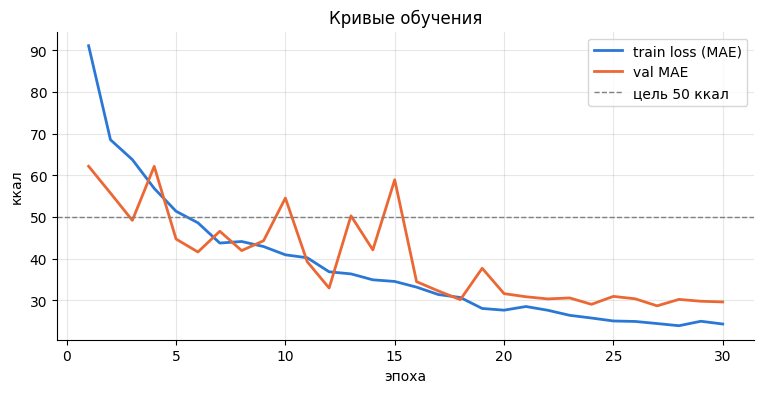

,epoch,train_loss,val_mae,val_rmse
0,1,91.12,62.19,99.65
1,2,68.55,55.76,82.93
2,3,63.79,49.21,75.43
3,4,56.89,62.17,95.94
4,5,51.39,44.73,72.12
5,6,48.63,41.62,64.89
6,7,43.77,46.60,72.57
7,8,44.14,41.96,65.74
8,9,42.93,44.31,71.08
9,10,40.95,54.57,87.17


In [29]:
history_df = pd.DataFrame(history)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(history_df["epoch"], history_df["train_loss"], color="#2a78d6", linewidth=2, label="train loss (MAE)")
ax.plot(history_df["epoch"], history_df["val_mae"], color="#eb6834", linewidth=2, label="val MAE")
ax.axhline(50, color="gray", linestyle="--", linewidth=1, label="цель 50 ккал")
ax.set(xlabel="эпоха", ylabel="ккал", title="Кривые обучения")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

history_df.round(2)

К концу обучения скачки val MAE затихают благодаря cosine scheduler, train и val идут близко друг к другу без признаков переобучения, а лучший val MAE = 28.70 получился на 27-й эпохе.

## 3. Сохранение артефакта

In [31]:
from google.colab import drive

drive.mount("/content/drive")
save_dir = "/content/drive/MyDrive/nutrition_models"
os.makedirs(save_dir, exist_ok=True)
shutil.copy(Config.SAVE_PATH, save_dir)

Mounted at /content/drive


'/content/drive/MyDrive/nutrition_models/best_model.pt'

## Этап 4. Валидация качества

### 1. Инференс на тестовой выборке

In [35]:
from transformers import AutoTokenizer

from scripts.config import Config
from scripts.dataset import load_data
from scripts.utils import MultimodalModel, get_dataloaders, predict

device = torch.device(Config.DEVICE if torch.cuda.is_available() else "cpu")
model = MultimodalModel(Config).to(device)
model.load_state_dict(torch.load(Config.SAVE_PATH, map_location=device))
model.eval()

tokenizer = AutoTokenizer.from_pretrained(Config.TEXT_MODEL_NAME)
_, _, test_loader = get_dataloaders(Config, tokenizer)
_, _, test_df = load_data(Config)

preds = []
with torch.no_grad():
    for batch in test_loader:
        preds.append(predict(model, batch, Config, device).cpu())

test_df["predicted"] = torch.cat(preds).numpy()
test_df["abs_error"] = (test_df["predicted"] - test_df["total_calories"]).abs()

print(f"Test MAE: {test_df['abs_error'].mean():.2f}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Test MAE: 35.23


Целевая метрика MAE = 35.23 < 50, следовательно, модель готова к интеграции в продукт.

### 2. Топ-5 блюд с самой большой ошибкой

In [33]:
top5 = test_df.sort_values("abs_error", ascending=False).head(5)
top5[["dish_id", "total_mass", "total_calories", "predicted", "abs_error", "ingredients"]].round(1)

,dish_id,total_mass,total_calories,predicted,abs_error,ingredients
86,dish_1566328805,488.0,927.8,576.700012,351.2,"cherry tomatoes, pizza, chicken, pineapple"
171,dish_1558630325,269.0,751.5,404.200012,347.3,"apple, garden salad, almonds"
298,dish_1558549806,203.0,782.0,466.899994,315.0,"almonds, white rice, spinach (raw)"
141,dish_1565811139,416.0,902.2,589.900024,312.3,"carrot, goat cheese, olive oil, broccoli, spinach (raw), chicken"
170,dish_1566501594,109.0,508.0,201.100006,306.9,brownies


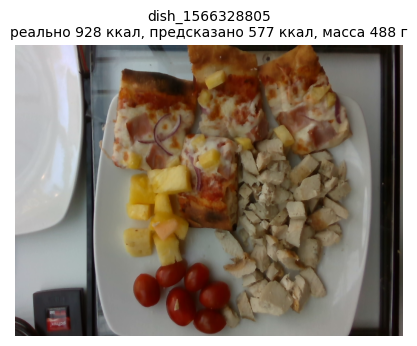

Ингредиенты: cherry tomatoes, pizza, chicken, pineapple


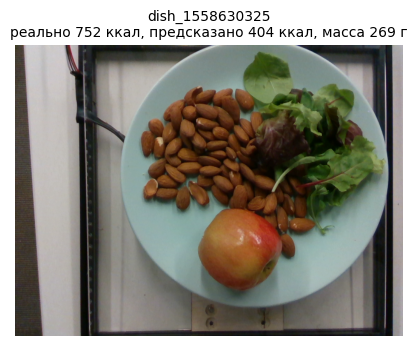

Ингредиенты: apple, garden salad, almonds


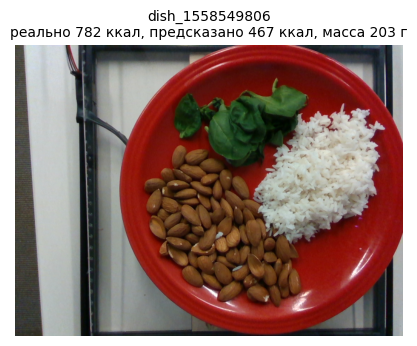

Ингредиенты: almonds, white rice, spinach (raw)


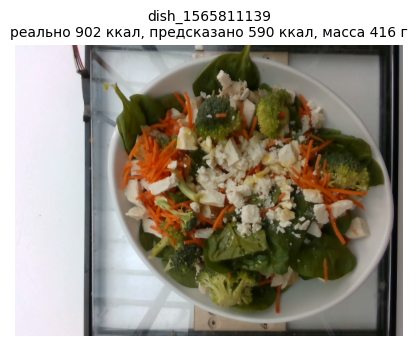

Ингредиенты: carrot, goat cheese, olive oil, broccoli, spinach (raw), chicken


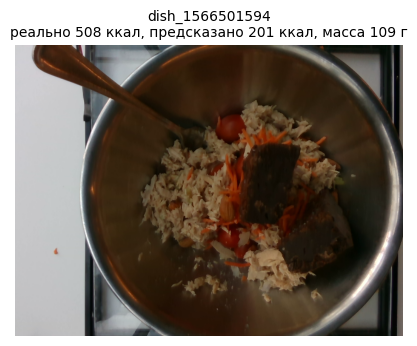

Ингредиенты: brownies


In [34]:
for _, row in top5.iterrows():
    image = Image.open(os.path.join(Config.DATA_DIR, "images", row["dish_id"], "rgb.png")).convert("RGB")
    plt.figure(figsize=(5, 4))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"{row['dish_id']}\nреально {row['total_calories']:.0f} ккал, предсказано {row['predicted']:.0f} ккал, "
              f"масса {row['total_mass']:.0f} г", fontsize=10)
    plt.show()
    print("Ингредиенты:", row["ingredients"] or "нет (только deprecated)")

### 3. Анализ ошибок

Все пять блюд модель недооценила на 300-350 ккал. Если пересчитать на грамм, у всех них калорийность очень высокая, от 1.9 до 4.7 ккал/г, тогда как медиана по датасету около 1.1. Модель предсказала для них 1.2-2.3 ккал/г, т.е. потянула ответ к более типичным значениям.

Разбор по блюдам:
- `dish_1566328805` (пицца, курица, ананас, черри, 488 г). Смешанное блюдо, где почти половину тарелки занимают лёгкие ананас, помидоры и курица, а основные калории даёт пицца, модель усреднила плотность по всей тарелке, также пицца обрезана краем кадра, а слева видна часть другой тарелки.
- `dish_1558630325` (миндаль, яблоко, салат, 269 г) и `dish_1558549806` (миндаль, рис, шпинат, 203 г). В обоих блюдах большую часть калорий дают орехи, у миндаля 5.78 ккал/г. В списке ингредиентов нет пропорций, поэтому по тексту не понять, что миндаля тут целая горсть, а на фото мелкие орехи выглядят как небольшая порция, вторая тарелка к тому же красная, хотя в данных почти везде белая посуда.
- `dish_1565811139` (шпинат, брокколи, морковь, курица, козий сыр, оливковое масло, 416 г). Визуально это лёгкий овощной салат, но много калорий дают масло и сыр, масло на фото почти не видно, и сколько его налили, модель узнать не может.
- `dish_1566501594` (brownies, 109 г). Похоже на ошибку разметки, потому что в ингредиентах только брауни, и 508 ккал на 109 г (4.7 ккал/г) как раз соответствует брауни, но на фото металлическая миска с рисом, морковью и помидорами, а брауни там всего два кусочка. К тому же снимок нетипичный, другая посуда, ложка в кадре и другой фон, модель видит рис с овощами и предсказывает плотность как у них.

Гипотезы для улучшения:
- обогатить текст калорийностью ингредиентов на 100 г из внешнего справочника (например, USDA), чтобы модель знала, что миндаль и масло очень калорийные;
- почистить разметку там, где фото не совпадает со списком ингредиентов;
- увеличить вес примеров с высокой плотностью в лоссе или предсказывать логарифм плотности, чтобы модель меньше тянула ответы к среднему.